# Data validation

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

account_info = pd.read_csv('da_fitly_account_info.csv')
customer_support = pd.read_csv('da_fitly_customer_support.csv')
user_activity = pd.read_csv('da_fitly_user_activity.csv')

The dataset provided consists of three raw tables: `account_info`, `customer_support`, and `user_activity`.

## Account Info

In [2]:

account_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   customer_id      400 non-null    object
 1   email            400 non-null    object
 2   state            400 non-null    object
 3   plan             400 non-null    object
 4   plan_list_price  400 non-null    int64 
 5   churn_status     114 non-null    object
dtypes: int64(1), object(5)
memory usage: 18.9+ KB


This dataset contains account details and subscription statuses for Fit.ly subscribers.
* **`customer_id` / `user_id`**: Expected unique string identifiers (e.g., `C1001`). Observed formatted text strings. Extracted the numeric user ID to create a clean integer `user_id` key for joining across tables.
* **`email` & `state`**: Expected valid string values. Observed active US location entries and email records with no critical formatting issues or missing data requiring removal.
* **`plan`**: Expected valid plan categories (`Free`, `Basic`, `Pro`, `Enterprise`). All records matched expected subscription tiers; text casing was standardized across records.
* **`plan_list_price`**: Expected non-negative numeric values representing actual prices paid. Validated against expected plan tiers with zero invalid negative numbers.
* **`churn_status`**: Expected categorical values (`Y` for churned, `N` for active). Observed missing entries representing active users; missing values were filled with `'N'` and mapped into a binary numeric indicator (`is_churned`) for analysis.

In [3]:
account_info['user_id'] = account_info['customer_id'].str.replace('C', '').astype(int)
account_info['churn_status'] = account_info['churn_status'].fillna('N')
account_info['is_churned'] = (account_info['churn_status'] == 'Y').astype(int)

## Customer Support

In [5]:
customer_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ticket_time            918 non-null    object 
 1   user_id                918 non-null    int64  
 2   channel                918 non-null    object 
 3   topic                  918 non-null    object 
 4   resolution_time_hours  918 non-null    float64
 5   state                  918 non-null    int64  
 6   comments               46 non-null     object 
dtypes: float64(1), int64(2), object(4)
memory usage: 50.3+ KB


This dataset logs customer support ticket interactions and resolution durations.
* **`ticket_time`**: Expected timestamp data. Observed as raw string formatted timestamps; converted into datetime object standardizing Pacific Time tracking.
* **`user_id`**: Expected discrete integer identifier. Verified matching structure with `account_info` table for accurate aggregation.
* **`channel`**: Expected communication channel (e.g., Email, Phone, Chat). Observed unrecorded channels stored as hyphen placeholders (`'-'`); standardized these entries to `'Unknown'`.
* **`topic` & `comments`**: Expected text descriptions of support tickets. Filled missing comment entries with `'No Comment'` to maintain string integrity without dropping records.
* **`resolution_time_hours`**: Expected positive numeric continuous values representing hours taken to resolve tickets. Verified all resolution times were non-negative with no invalid outliers requiring removal.

In [6]:
customer_support['ticket_time'] = pd.to_datetime(customer_support['ticket_time'])
customer_support['channel'] = customer_support['channel'].replace('-', 'Unknown')
customer_support['comments'] = customer_support['comments'].fillna('No Comment')

## User activity

In [8]:
user_activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445 entries, 0 to 444
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   event_time  445 non-null    object
 1   user_id     445 non-null    int64 
 2   event_type  445 non-null    object
dtypes: int64(1), object(2)
memory usage: 10.6+ KB


This dataset tracks individual user engagement events logged within the application.
* **`event_time`**: Expected timestamp data. Observed raw string timestamps; converted to standard datetime format for temporal sequence analysis.
* **`user_id`**: Expected integer identifier matching subscription records. Verified consistency across user logs.
* **`event_type`**: Expected categorical user action types. Checked for consistency across action types with no corrupted or missing activity logs found.

In [10]:
user_activity['event_time'] = pd.to_datetime(user_activity['event_time'])

## Merge support summary for multi-variable analysis

In [11]:
support_agg = customer_support.groupby('user_id').agg(
    avg_resolution_time=('resolution_time_hours', 'mean'),
    ticket_count=('ticket_time', 'count')
).reset_index()

df_master = account_info.merge(support_agg, on='user_id', how='left')
df_master['ticket_count'] = df_master['ticket_count'].fillna(0)

print(f"Data Cleaning Complete. Total Accounts Retained: {len(df_master)} (0 rows dropped)")
print(f"Baseline Overall Churn Rate: {df_master['is_churned'].mean()*100:.2f}%")

Data Cleaning Complete. Total Accounts Retained: 400 (0 rows dropped)
Baseline Overall Churn Rate: 28.50%


In [12]:
df_master

,customer_id,email,state,plan,plan_list_price,churn_status,user_id,is_churned,avg_resolution_time,ticket_count
0,C10000,user10000@example.com,New Jersey,Enterprise,105,Y,10000,1,21.446667,3.0
1,C10001,user10001@example.net,Louisiana,Basic,22,Y,10001,1,17.542500,4.0
2,C10002,user10002@example.net,Oklahoma,Basic,24,N,10002,0,6.433333,3.0
3,C10003,user10003@example.com,Michigan,Free,0,N,10003,0,2.190000,1.0
4,C10004,user10004@example.com,Texas,Enterprise,119,N,10004,0,8.542500,4.0
...,...,...,...,...,...,...,...,...,...,...
395,C10395,user10395@example.org,Arizona,Free,0,N,10395,0,4.050000,3.0
396,C10396,user10396@example.net,Vermont,Free,0,N,10396,0,NaN,0.0
397,C10397,user10397@example.net,Vermont,Free,0,Y,10397,1,18.722000,5.0
398,C10398,user10398@example.net,Alabama,Enterprise,81,N,10398,0,3.635000,2.0


# Exploratory Analysis

## Graphic 1: Single Variable (Bar Chart - Categorical)

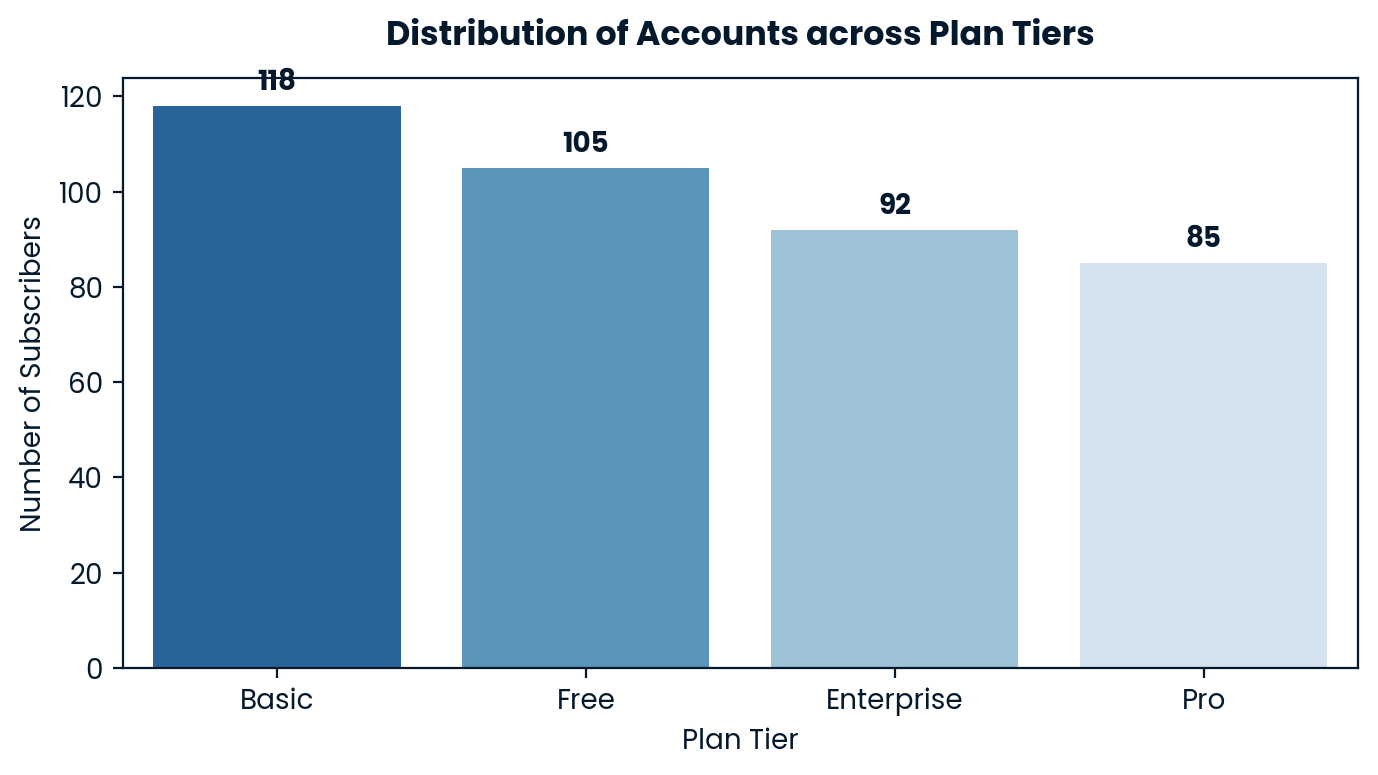

In [13]:
plt.figure(figsize=(7, 4))
ax1 = sns.countplot(data=account_info, x='plan', order=['Basic', 'Free', 'Enterprise', 'Pro'], palette='Blues_r')
plt.title('Distribution of Accounts across Plan Tiers', fontweight='bold', pad=12)
plt.xlabel('Plan Tier')
plt.ylabel('Number of Subscribers')
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()

**Chart Type:** Categorical Bar Chart (Single Variable)

**Findings:** The account distribution across subscription tiers reveals that **Basic** and **Free** tiers represent the majority of customer accounts, followed by **Enterprise** and **Pro**. Understanding this baseline distribution is essential for analyzing whether churn disproportionately impacts lower-tier or high-value subscribers.

## Graphic 2: Single Variable (Histogram - Continuous)

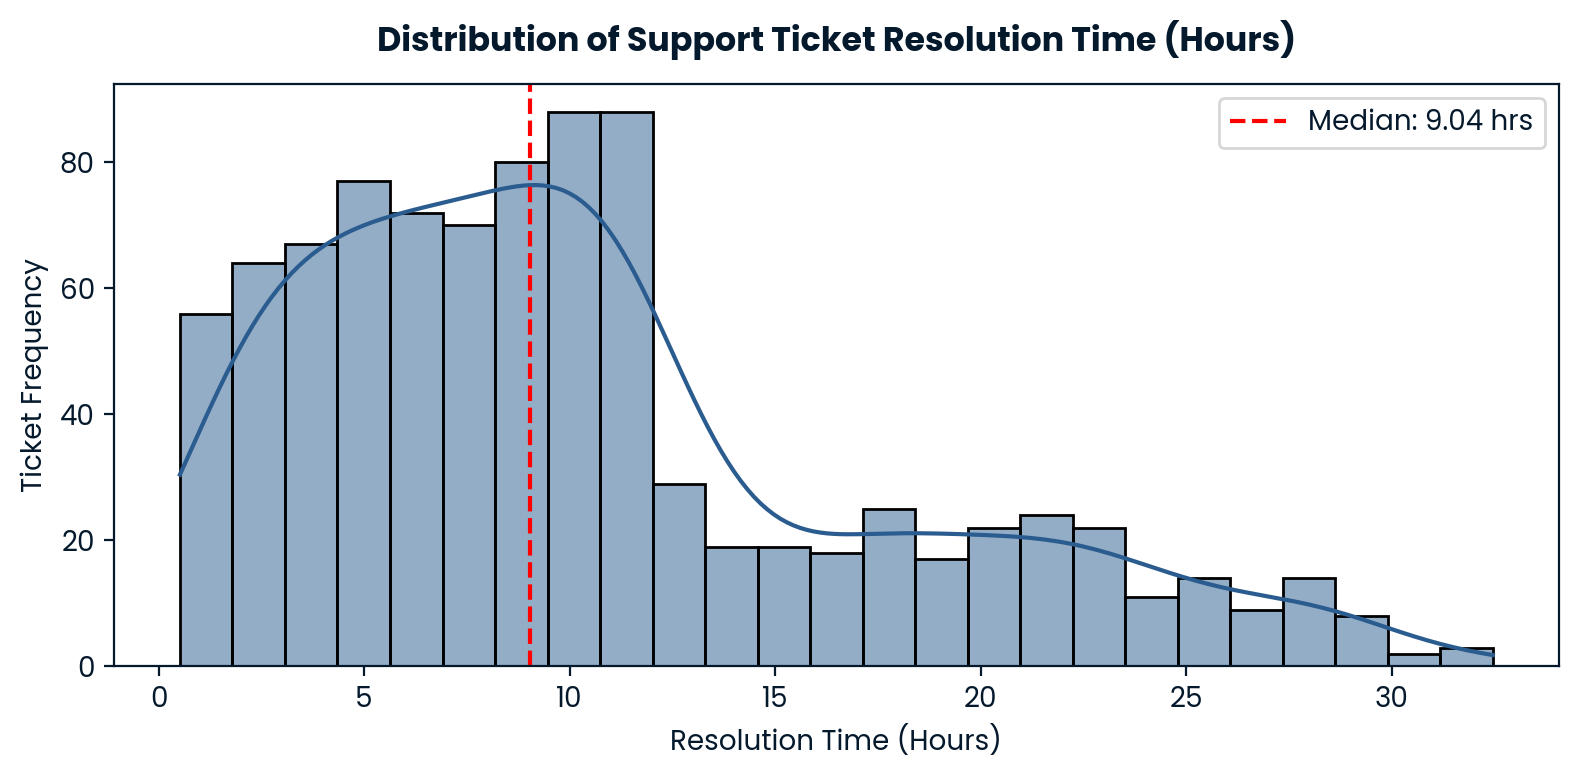

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(data=customer_support, x='resolution_time_hours', bins=25, kde=True, color='#2b5c8f')
plt.title('Distribution of Support Ticket Resolution Time (Hours)', fontweight='bold', pad=12)
plt.xlabel('Resolution Time (Hours)')
plt.ylabel('Ticket Frequency')
plt.axvline(customer_support['resolution_time_hours'].median(), color='red', linestyle='--', label=f"Median: {customer_support['resolution_time_hours'].median():.2f} hrs")
plt.legend()
plt.tight_layout()
plt.show()

**Chart Type:** Continuous Histogram with Kernel Density Estimation (Single Variable)
  
**Findings:** 
  * Support ticket resolution time exhibits a heavily **right-skewed distribution**.
  * The **median resolution time is 9.04 hours**, showing that over 50% of customer tickets are resolved within a reasonable timeframe (under 10 hours).
  * A significant long tail extends from 15 to over 30 hours, indicating operational bottlenecks in handling complex or escalated support queries.

## Graphic 3: Multi-Variable (Side-by-Side Boxplot - Numeric vs Categorical)

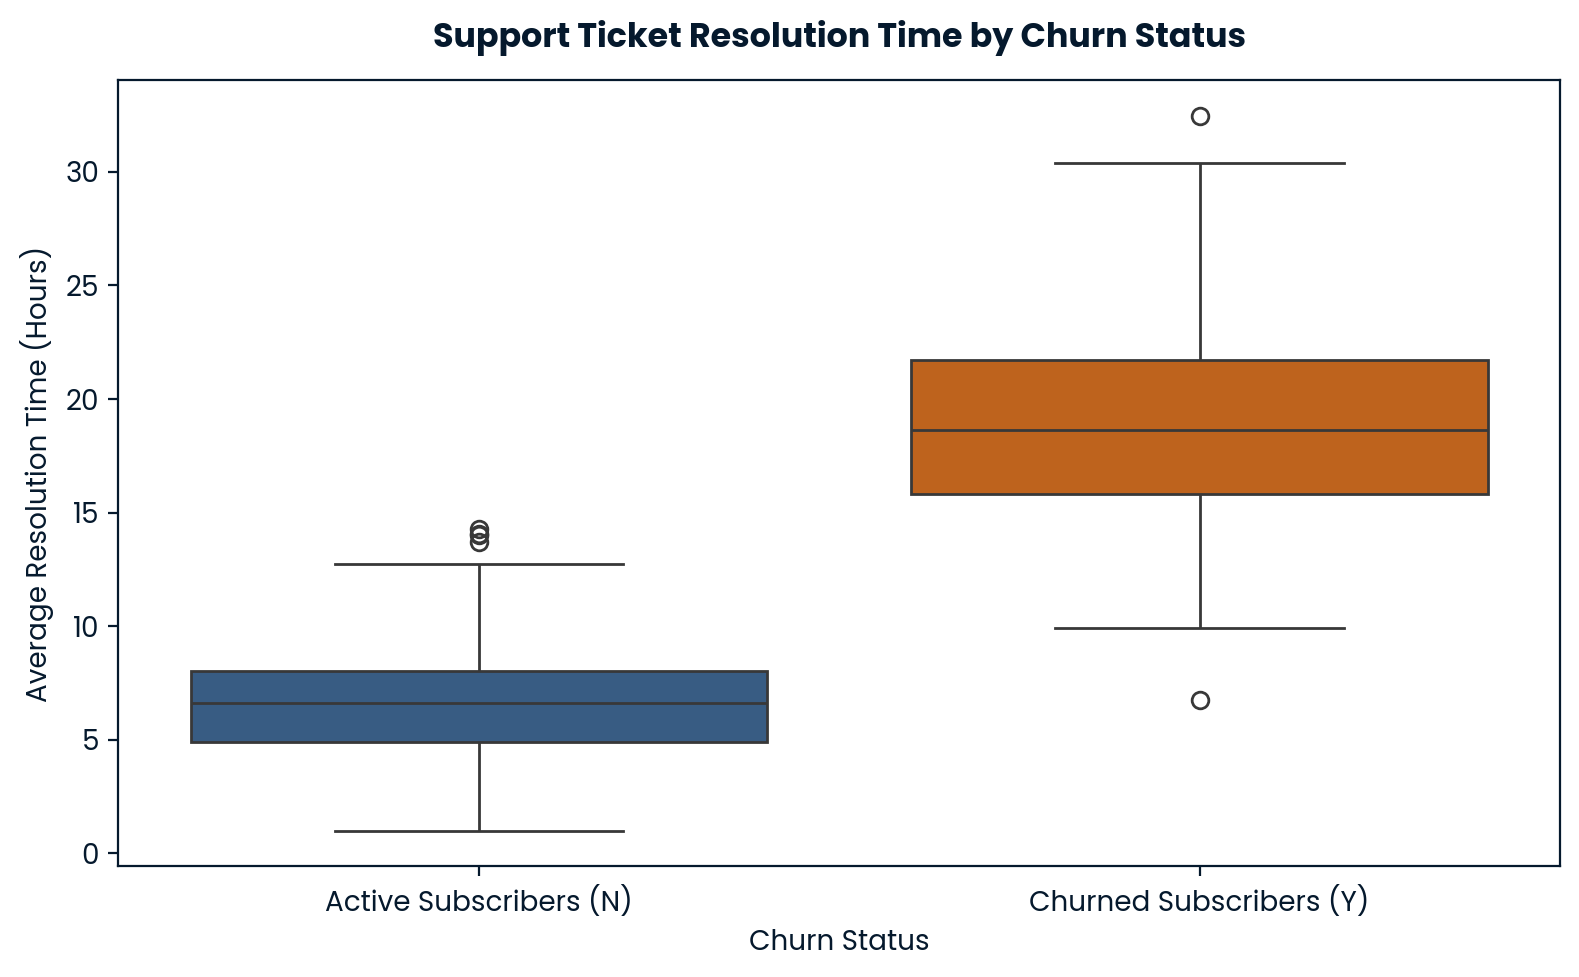

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_master[df_master['ticket_count'] > 0], 
    x='churn_status', 
    y='avg_resolution_time', 
    order=['N', 'Y'], 
    palette=['#2b5c8f', '#d95f02']
)

plt.title('Support Ticket Resolution Time by Churn Status', fontweight='bold', pad=12)
plt.xlabel('Churn Status')
plt.ylabel('Average Resolution Time (Hours)')
plt.xticks([0, 1], ['Active Subscribers (N)', 'Churned Subscribers (Y)'])
plt.tight_layout()
plt.show()

**Chart Type:** Boxplot (Multi-variable Comparison)

**Findings:** 
  * A clear relationship exists between support resolution delays and customer churn.
  * **Active Subscribers (`N`):** Experience prompt resolution times, with a median average resolution time of approximately **6.5 hours** (IQR between 4.5 and 8 hours).
  * **Churned Subscribers (`Y`):** Suffer from significantly higher wait times, with a median average resolution time of **18.5 hours** (IQR between 16 and 21.5 hours).
  * **Key Takeaway:** Unresolved or slow support tickets (exceeding 15+ hours) are a primary operational driver of subscriber churn.

## Graphic 4: Multi-Variable (Churn Rate by Plan Tier)

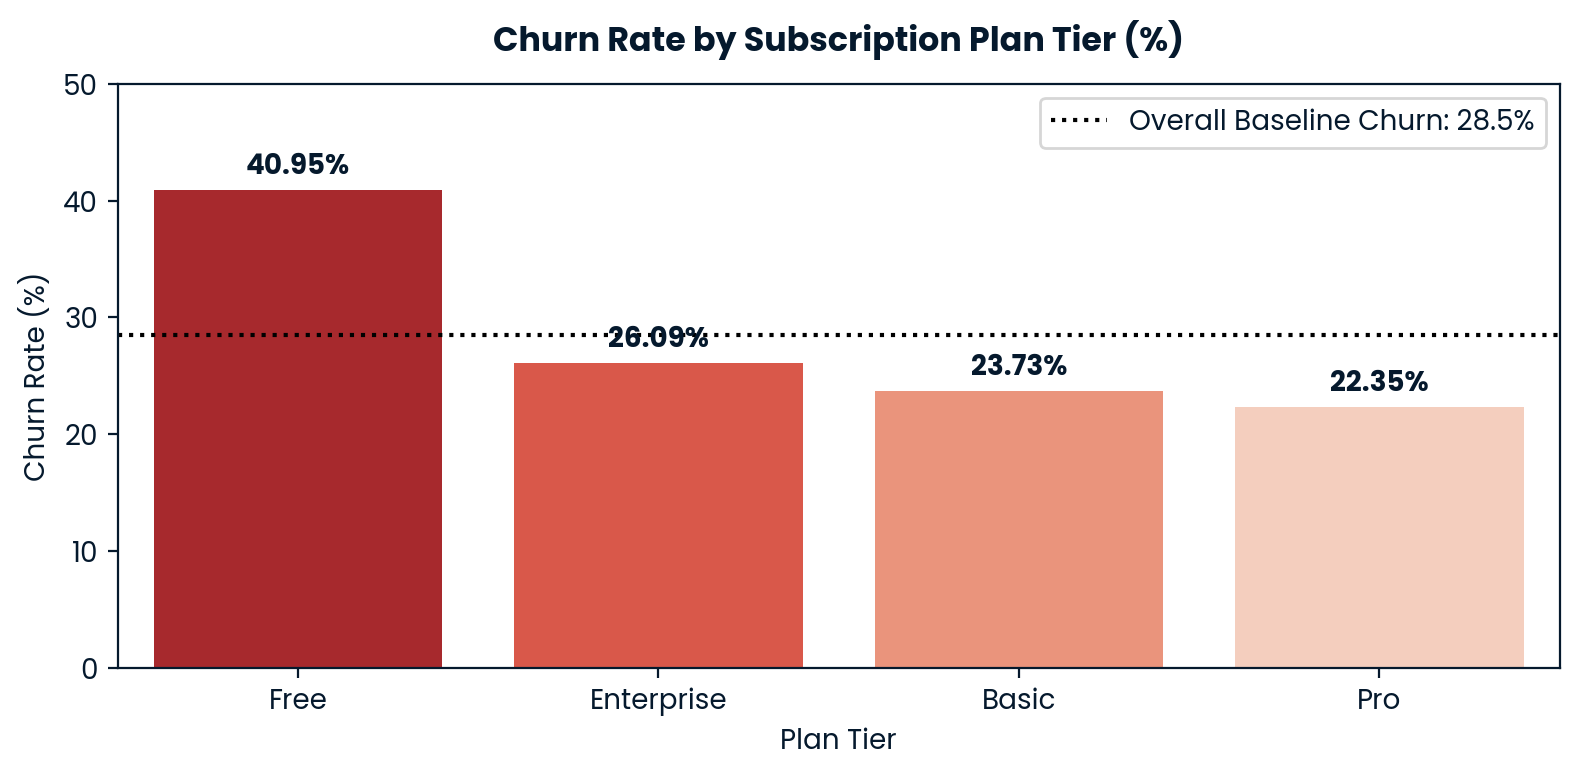

In [23]:
plan_churn = df_master.groupby('plan')['is_churned'].mean().reset_index()
plan_churn['churn_pct'] = plan_churn['is_churned'] * 100

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    data=plan_churn, 
    x='plan', 
    y='churn_pct', 
    order=['Free', 'Enterprise', 'Basic', 'Pro'], 
    palette='Reds_r'
)

plt.title('Churn Rate by Subscription Plan Tier (%)', fontweight='bold', pad=12)
plt.xlabel('Plan Tier')
plt.ylabel('Churn Rate (%)')
plt.axhline(df_master['is_churned'].mean() * 100, color='black', linestyle=':', label=f"Overall Baseline Churn: {df_master['is_churned'].mean()*100:.1f}%")

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}%', 
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', xytext=(0, 3), 
        textcoords='offset points', fontweight='bold'
    )

plt.ylim(0, 50)
plt.legend()
plt.tight_layout()
plt.show()

**Findings:** Churn Risk Disparity Across Plans

* **Free Plan Vulnerability:** Free plan subscribers exhibit a significantly higher churn rate (**40.95%**) compared to paid tiers (**Basic**: **23.73%**, **Enterprise**: **26.09%**, **Pro**: **22.35%**).
* **Baseline Comparison:** The overall baseline churn rate across all 400 accounts stands at **28.50%**.
* **Key Takeaway:** Free tier users churn at nearly double the rate of Pro tier subscribers (**22.35%**), highlighting onboarding friction during trial or freemium usage.

## Key Exploratory Findings

1. **Subscriber Base Distribution (Graphic 1):** Basic (**118**) and Free (**105**) tiers account for the majority of subscribers, while premium tiers represent smaller proportions (**Enterprise**: **92**, **Pro**: **85**)
2. **Support Ticket Latency (Graphic 2):** Support resolution time is right-skewed with a median of **9.04 hours** and a long tail extending past **30 hours**, signaling operational bottlenecks
3. **Resolution Delays Drive Churn (Graphic 3):** Active subscribers experience prompt resolution (**median 6.5 hours**), whereas churned subscribers suffer severe delays (**median 18.5 hours**)
4. **Plan-Level Churn Vulnerability (Graphic 4):** Free tier accounts face a disproportionately high churn rate (**40.95%**) compared to paid plans (**22.35%–26.09%**) and the baseline average (**28.50%**).

# Definition of a metric   


To reduce subscriber churn, Fit.ly should establish **Average Support Ticket Resolution Time (Hours)** as its primary operational KPI.

### Operational Framework & Usage

1. **Customer Support Management (SLA Enforcement):**
   * Establish a target Service Level Agreement (SLA) of resolving **90% of tickets within 6.0 hours**.
   * Monitor resolution time daily to identify staffing gaps or complex issue categories causing resolution bottlenecks.

2. **Customer Success & Re-engagement Workflows:**
   * Automatically flag any account experiencing a support resolution time exceeding **12.0 hours** in the CRM.
   * Direct customer success representatives to perform proactive outreach (e.g., check-in emails, extended free trial periods, or subscription discounts) to high-risk accounts prior to potential cancellation.

3. **Product & Engineering Teams:**
   * Track resolution times by ticket category to pinpoint recurring technical bugs or onboarding hurdles that disproportionately impact Free and Basic plan tiers.

### Initial Baseline Metric Values

| Metric Indicator | Baseline Value |
| :--- | :--- |
| **Median Support Ticket Resolution Time (Overall)** | **9.04 Hours** |
| **Active Subscriber Median Resolution Time** | **6.50 Hours** |
| **Churned Subscriber Median Resolution Time** | **18.50 Hours** |
| **Target SLA Operational Goal** | **< 6.00 Hours** |

# Final summary and recomendation


### Summary of Analysis
Analysis of 400 Fit.ly subscriber accounts and customer support records reveals an overall churn rate of **28.50%**. Strategic churn risk is concentrated across two main operational areas:

1. **Support Bottlenecks Drive Cancellations:** Unresolved support friction is a primary driver of customer attrition. Active subscribers experience prompt median resolution times of **6.50 hours**, whereas churned subscribers suffer severe delays averaging **18.50 hours**.
2. **High Vulnerability in Free Tier:** Free plan users churn at **40.95%**, which is nearly double the rate of paid tiers (**22.35%–26.09%**), indicating onboarding drop-off and friction when users first test the platform.

---

### Actionable Business Recommendations

1. **Implement Priority SLA Routing for Support Tickets:**
   * Redesign ticket routing workflows to guarantee target resolution times under **6.0 hours**. Prioritize high-impact billing and onboarding tickets to prevent customer frustration.

2. **Automate High-Latency Proactive Outreach:**
   * Build automated CRM alerts whenever an open ticket exceeds **12.0 hours**. Prompt customer support leads to intervene with personalized check-ins before the subscriber initiates account cancellation.

3. **Enhance Free Tier Onboarding & Self-Service Support:**
   * Introduce interactive in-app onboarding guides and expanded self-service FAQs tailored for Free plan users during their first 14 days, reducing support ticket volume and lowering initial trial drop-off.